# 06 — Experiments from research round 2
From `docs/reports/Air raid forecast data and formulation.md`, same 6-fold walk-forward protocol as notebook 05.

| # | Experiment | Model(s) |
|---|---|---|
| 1 | **Raion-alerting regime** — alerting moved from whole-oblast to raion level (detected from data: oblast-level share < 10 %) | `v2 +regime flag`, `v2 post-switch only` (train only on data after the switch) |
| 2 | **Raion-share features** — share of raions on alert in the oblast, border neighbours (now, −15…−120 min), lift-weighted upstream oblasts, whole country | `v4` (= v2 + raion share + regime flag) |
| 4 | **Simultaneous-start diagnostic** — how much error comes from near-nationwide simultaneous starts (MiG-31K / ballistic-type alerts, ≈ no lead time)? | evaluation split, no new model |

Baseline = `v2` from notebook 05 (mean per-oblast PR-AUC 0.222 ± 0.020 at 30 min).

In [1]:
import os, sys
from pathlib import Path
if not Path("src").is_dir() and Path("../src").is_dir():
    os.chdir("..")                      # notebooks/ → project root, where data/ and src/ live
sys.path.insert(0, str(Path.cwd()))
import json, sys, time, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from pathlib import Path
from sklearn.metrics import average_precision_score, brier_score_loss

sys.path.insert(0, str(Path.cwd()))
from src.data import load_clean, sub_grid, raion_share_grid, regime_switch_date
from src.features import (build_features_v4, build_targets, compute_lift, future_starts, HORIZONS, STEP,
                          OWN, CAL, SPATIAL, WAVE, ADJ_F, SUB, RAION, REGIME, nbr_cols)

sns.set_theme(style="whitegrid")
DATA_DIR = Path("data")
state_all  = pd.read_parquet(DATA_DIR / "state_5min.parquet")
starts_all = pd.read_parquet(DATA_DIR / "starts_5min.parquet")
raw = load_clean(DATA_DIR / "official_data_en.csv")
REGIME_DATE = regime_switch_date(raw)
print("raion-alerting regime from:", REGIME_DATE.date())

END = state_all.index[-1]
N_FOLDS, TEST_DAYS, ES_DAYS, TRAIN_DAYS = 6, 30, 30, 365
EMBARGO, TRAIN_EVERY = pd.Timedelta("60min"), 2
folds = []
for k in range(N_FOLDS):
    te = (END - pd.Timedelta(days=TEST_DAYS * k)).floor("5min"); ts = te - pd.Timedelta(days=TEST_DAYS)
    es = ts - pd.Timedelta(days=ES_DAYS)
    folds.append(dict(fold=N_FOLDS - k, train_start=es - pd.Timedelta(days=TRAIN_DAYS), es_start=es, test_start=ts, test_end=te))
folds = pd.DataFrame(folds).sort_values("fold").reset_index(drop=True)
assert (folds.train_start < REGIME_DATE).all() and (folds.es_start > REGIME_DATE).all()

lo = folds.train_start.min() - pd.Timedelta(days=10)
state_all, starts_all = state_all.loc[lo:], starts_all.loc[lo:]
oblasts = list(state_all.columns)
sub_all, full_all = sub_grid(raw, state_all.index, oblasts)
rs_all = raion_share_grid(raw, state_all.index, oblasts)
folds.assign(post_switch_train_days=(folds.es_start - REGIME_DATE).dt.days)

raion-alerting regime from: 2025-11-15


,fold,train_start,es_start,test_start,test_end,post_switch_train_days
0,1,2025-02-09 07:40:00+02:00,2026-02-09 07:40:00+02:00,2026-03-11 07:40:00+02:00,2026-04-10 08:40:00+03:00,86
1,2,2025-03-11 07:40:00+02:00,2026-03-11 07:40:00+02:00,2026-04-10 08:40:00+03:00,2026-05-10 08:40:00+03:00,116
2,3,2025-04-10 08:40:00+03:00,2026-04-10 08:40:00+03:00,2026-05-10 08:40:00+03:00,2026-06-09 08:40:00+03:00,146
3,4,2025-05-10 08:40:00+03:00,2026-05-10 08:40:00+03:00,2026-06-09 08:40:00+03:00,2026-07-09 08:40:00+03:00,176
4,5,2025-06-09 08:40:00+03:00,2026-06-09 08:40:00+03:00,2026-07-09 08:40:00+03:00,2026-08-08 08:40:00+03:00,206
5,6,2025-07-09 08:40:00+03:00,2026-07-09 08:40:00+03:00,2026-08-08 08:40:00+03:00,2026-09-07 08:40:00+03:00,236


In [2]:
V2 = OWN + CAL + SPATIAL + nbr_cols() + WAVE + ADJ_F + SUB
CONFIGS = {                     # name: (features, train only after regime switch?)
    "v2":                    (V2, False),
    "v2 +regime flag":       (V2 + REGIME, False),
    "v2 post-switch only":   (V2, True),
    "v4 (+raion share)":     (V2 + RAION + REGIME, False),
    "v4 post-switch only":   (V2 + RAION, True),
}
PARAMS = dict(objective="binary", learning_rate=0.03, num_leaves=63, min_data_in_leaf=500,
              feature_fraction=0.7, bagging_fraction=0.7, bagging_freq=1, lambda_l2=5.0, verbose=-1, seed=0)

def recency_weight(X, ref, hl=180):
    age = (ref - X.index.get_level_values("time")).total_seconds() / 86400
    return np.asarray(0.5 ** (age / hl), dtype=float)

def climatology(Xtr, ytr, X):
    tab = ytr.groupby([Xtr.index.get_level_values("oblast"), (Xtr.index.get_level_values("time") + STEP).hour]).mean()
    key = pd.MultiIndex.from_arrays([X.index.get_level_values("oblast"), (X.index.get_level_values("time") + STEP).hour])
    return tab.reindex(key).values

# Experiment 4: "simultaneous" starts = oblast start in a 5-min bin where ≥ SIM_N oblasts start together
SIM_N = 8
n_bin = starts_all.sum(axis=1)
sim_starts = starts_all.mul(n_bin >= SIM_N, axis=0)
nonsim_starts = starts_all - sim_starts
print(f"share of starts that are simultaneous (≥{SIM_N} oblasts in one bin): {sim_starts.values.sum() / starts_all.values.sum():.3f}")

share of starts that are simultaneous (≥8 oblasts in one bin): 0.100


## Run all folds

In [3]:
all_preds = []
for f in folds.itertuples():
    t0 = time.time()
    lift  = compute_lift(starts_all, f.es_start)
    front = state_all.loc[f.train_start:f.es_start].mean().pipe(lambda s: s[s > .25].index.tolist())
    idx = state_all.index
    T = {"train": idx[(idx >= f.train_start) & (idx < f.es_start - EMBARGO)][::TRAIN_EVERY],
         "es":    idx[(idx >= f.es_start) & (idx < f.test_start - EMBARGO)],
         "test":  idx[(idx >= f.test_start) & (idx < min(f.test_end, idx[-1]) - EMBARGO)]}
    D = {}
    for part, t in T.items():
        X = build_features_v4(state_all, starts_all, lift, t, sub_all, full_all, rs_all, REGIME_DATE).astype(np.float32)
        X["oblast"] = pd.Categorical(X.index.get_level_values("oblast"), categories=oblasts)
        D[part] = (X, build_targets(starts_all, t))
    Xtr, Ytr = D["train"]; Xes, Yes = D["es"]; Xte, Yte = D["test"]
    post = np.asarray(Xtr.index.get_level_values("time") >= REGIME_DATE)
    w = recency_weight(Xtr, f.es_start)
    for h, k in HORIZONS.items():
        y_nonsim = future_starts(nonsim_starts, k).loc[T["test"]].stack(future_stack=True).reindex(Xte.index).values
        P = pd.DataFrame({"y": Yte[f"y_{h}"].values, "y_nonsim": y_nonsim,
                          "Climatology": climatology(Xtr, Ytr[f"y_{h}"], Xte)}, index=Xte.index)
        for name, (feats, post_only) in CONFIGS.items():
            m_ = post if post_only else np.ones(len(Xtr), bool)
            dtr = lgb.Dataset(Xtr.loc[m_, feats + ["oblast"]], Ytr.loc[m_, f"y_{h}"], weight=w[m_])
            des = lgb.Dataset(Xes[feats + ["oblast"]], Yes[f"y_{h}"], reference=dtr)
            mdl = lgb.train(PARAMS, dtr, 4000, valid_sets=[des], callbacks=[lgb.early_stopping(200, verbose=False)])
            P[name] = mdl.predict(Xte[feats + ["oblast"]])
            if f.fold == folds.fold.max() and h == "30min" and name == "v4 (+raion share)":
                last_model = mdl
        P["fold"], P["horizon"] = f.fold, h
        P["front"] = P.index.get_level_values("oblast").isin(front)
        all_preds.append(P)
    print(f"fold {f.fold}: test {f.test_start.date()}→{f.test_end.date()}, post-switch train rows {post.mean():.0%}  ({time.time()-t0:.0f}s)")
    del D, Xtr, Xes, Xte; gc.collect()

preds = pd.concat(all_preds)
preds.to_parquet(DATA_DIR / "preds_06_experiments.parquet")
MODELS = ["Climatology"] + list(CONFIGS)

fold 1: test 2026-03-11→2026-04-10, post-switch train rows 24%  (341s)


fold 2: test 2026-04-10→2026-05-10, post-switch train rows 32%  (310s)


fold 3: test 2026-05-10→2026-06-09, post-switch train rows 40%  (422s)


fold 4: test 2026-06-09→2026-07-09, post-switch train rows 48%  (356s)


fold 5: test 2026-07-09→2026-08-08, post-switch train rows 57%  (368s)


fold 6: test 2026-08-08→2026-09-07, post-switch train rows 65%  (393s)


## Results (experiments 1 & 2)

In [4]:
def mean_ap(P, m, ycol="y"):
    s = [average_precision_score(g[ycol], g[m]) for _, g in P.groupby(level="oblast") if g[ycol].sum() >= 5]
    return np.mean(s)

rows = []
for (fold, h), P in preds.groupby(["fold", "horizon"]):
    for grp, sel in {"all": P, "rear": P[~P.front], "frontline": P[P.front]}.items():
        sel = sel.dropna(subset=MODELS + ["y"])
        bs_c = brier_score_loss(sel.y, sel.Climatology)
        for m in MODELS:
            rows.append({"fold": fold, "horizon": h, "group": grp, "model": m, "mean AP": mean_ap(sel, m),
                         "BSS": 1 - brier_score_loss(sel.y, sel[m].clip(0, 1)) / bs_c})
res = pd.DataFrame(rows)
res.to_csv(DATA_DIR / "results_06_experiments.csv", index=False)

for grp in ["all", "rear", "frontline"]:
    t = res.query("group == @grp").groupby(["model", "horizon"])["mean AP"].agg(["mean", "std"])
    t = (t["mean"].round(3).astype(str) + " ± " + t["std"].round(3).astype(str)).unstack().loc[MODELS, list(HORIZONS)]
    print(f"\n=== mean per-oblast PR-AUC — {grp} — {N_FOLDS} folds ===\n{t}")


=== mean per-oblast PR-AUC — all — 6 folds ===
horizon                      15min          30min          60min
model                                                           
Climatology          0.034 ± 0.005  0.069 ± 0.009   0.13 ± 0.017
v2                   0.152 ± 0.018   0.222 ± 0.02  0.295 ± 0.026
v2 +regime flag      0.152 ± 0.017   0.22 ± 0.019  0.297 ± 0.027
v2 post-switch only  0.153 ± 0.023   0.22 ± 0.022  0.291 ± 0.031
v4 (+raion share)    0.156 ± 0.015  0.227 ± 0.021  0.298 ± 0.027
v4 post-switch only   0.155 ± 0.02   0.22 ± 0.022  0.292 ± 0.029

=== mean per-oblast PR-AUC — rear — 6 folds ===
horizon                      15min          30min          60min
model                                                           
Climatology          0.026 ± 0.005   0.052 ± 0.01    0.1 ± 0.019
v2                   0.097 ± 0.023  0.147 ± 0.031   0.21 ± 0.037
v2 +regime flag      0.097 ± 0.023  0.144 ± 0.029  0.213 ± 0.038
v2 post-switch only  0.102 ± 0.029   0.147 ± 0.03  0.207 ±

In [5]:
cmp = []
for h in HORIZONS:
    for grp in ["all", "rear", "frontline"]:
        t = res.query("horizon == @h and group == @grp").pivot(index="fold", columns="model", values="mean AP")
        for m in MODELS[2:]:
            d = t[m] - t["v2"]
            cmp.append({"horizon": h, "group": grp, "model − v2": m, "mean Δ": d.mean(), "min Δ": d.min(),
                        "max Δ": d.max(), "folds won": f"{(d > 0).sum()}/{len(d)}"})
cmp = pd.DataFrame(cmp)
cmp.round(4)

,horizon,group,model − v2,mean Δ,min Δ,max Δ,folds won
0,15min,all,v2 +regime flag,-0.0005,-0.0057,0.0051,3/6
1,15min,all,v2 post-switch only,0.0011,-0.0053,0.0107,3/6
2,15min,all,v4 (+raion share),0.0035,-0.0052,0.0128,4/6
3,15min,all,v4 post-switch only,0.0031,-0.0072,0.0120,4/6
4,15min,rear,v2 +regime flag,-0.0000,-0.0063,0.0040,4/6
5,15min,rear,v2 post-switch only,0.0046,-0.0015,0.0132,4/6
6,15min,rear,v4 (+raion share),0.0071,-0.0018,0.0163,5/6
7,15min,rear,v4 post-switch only,0.0096,-0.0044,0.0219,5/6
8,15min,frontline,v2 +regime flag,-0.0011,-0.0134,0.0077,4/6
9,15min,frontline,v2 post-switch only,-0.0066,-0.0187,0.0045,1/6


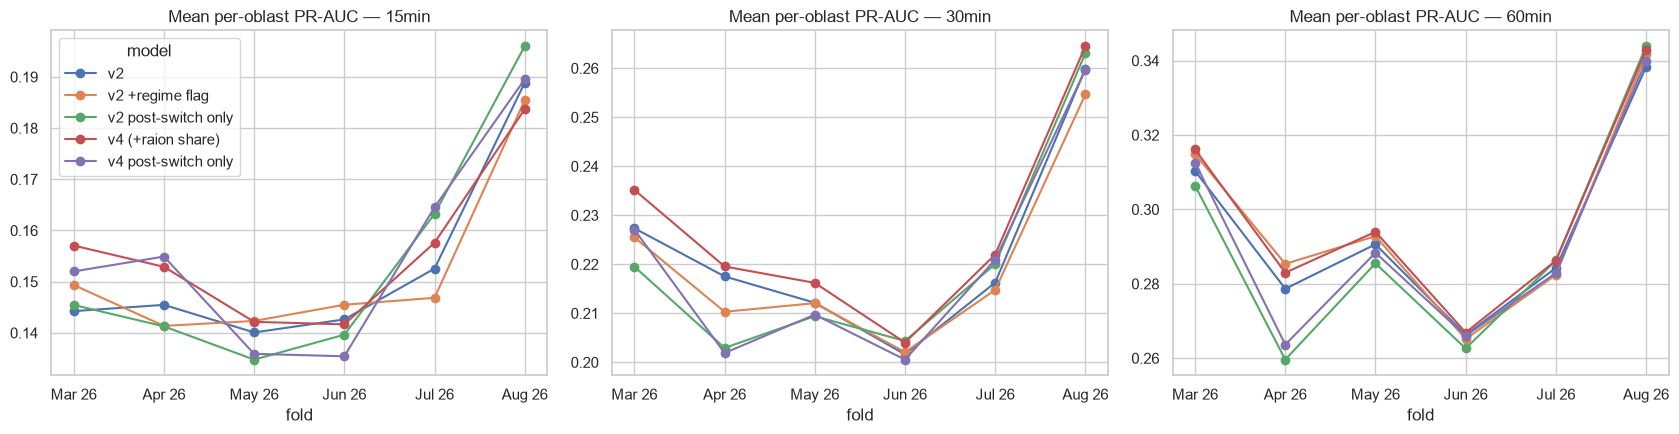

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, h in zip(ax, HORIZONS):
    t = res.query("horizon == @h and group == 'all'").pivot(index="fold", columns="model", values="mean AP")[MODELS[1:]]
    t.plot(marker="o", ax=a, legend=(h == "15min"), title=f"Mean per-oblast PR-AUC — {h}")
    a.set_xticks(folds.fold); a.set_xticklabels([d.strftime("%b %y") for d in folds.test_start])
plt.tight_layout(); plt.show()

gain share of raion-share features: 0.17


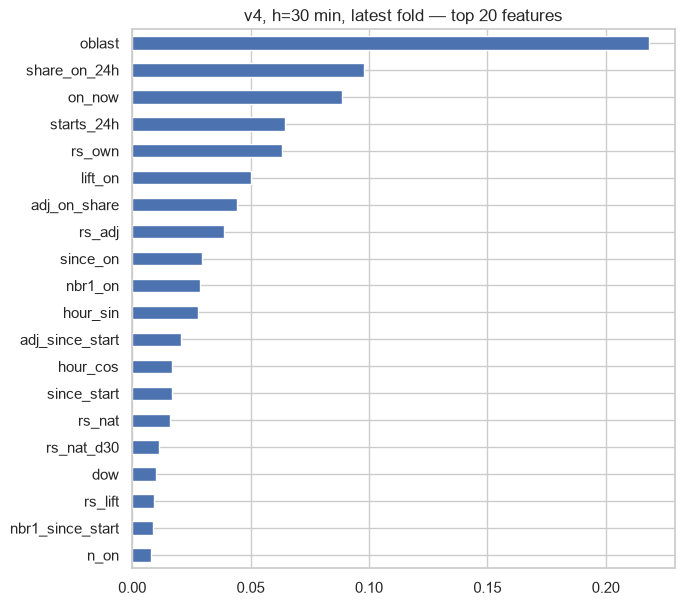

In [7]:
imp = pd.Series(last_model.feature_importance("gain"), index=last_model.feature_name()); imp /= imp.sum()
print("gain share of raion-share features:", round(imp[[c for c in imp.index if c.startswith("rs_")]].sum(), 3))
imp.sort_values().tail(20).plot.barh(figsize=(7, 7), title="v4, h=30 min, latest fold — top 20 features"); plt.show()

## Experiment 4 — simultaneous-start diagnostic
Positives caused **only** by simultaneous near-nationwide starts are removed (rows with `y=1` and `y_nonsim=0`);
negatives are kept. If PR-AUC rises a lot, a large part of the remaining error is these "no-lead-time" events.

In [8]:
diag = []
for (fold, h), P in preds.groupby(["fold", "horizon"]):
    P = P.dropna(subset=["y", "y_nonsim"])
    keep = ~((P.y == 1) & (P.y_nonsim == 0))
    for m in ["Climatology", "v2", "v4 (+raion share)"]:
        diag.append({"fold": fold, "horizon": h, "model": m,
                     "share of positives that are simultaneous-only": 1 - keep[P.y == 1].mean(),
                     "mean AP (all events)": mean_ap(P, m),
                     "mean AP (excl. simultaneous)": mean_ap(P[keep], m)})
diag = pd.DataFrame(diag).groupby(["model", "horizon"]).mean(numeric_only=True).drop(columns="fold")
diag.round(3)

share of positives that are simultaneous-only  \
model             horizon                                                  
Climatology       15min                                            0.061   
                  30min                                            0.061   
                  60min                                            0.060   
v2                15min                                            0.061   
                  30min                                            0.061   
                  60min                                            0.060   
v4 (+raion share) 15min                                            0.061   
                  30min                                            0.061   
                  60min                                            0.060   

                           mean AP (all events)  mean AP (excl. simultaneous)  
model             horizon                                                      
Climatology       15min                   0.034                         0.034  
                  30min                   0.069                         0.066  
                  60min                   0.130                         0.125  
v2                15min                   0.152                         0.166  
                  30min                   0.222                         0.249  
                  60min                   0.295                         0.321  
v4 (+raion share) 15min                   0.156                         0.171  
                  30min                   0.227                         0.255  
                  60min                   0.298                         0.323

## Conclusions (fill in after running)
- Exp 1 (regime): …
- Exp 2 (raion share): …
- Exp 4 (simultaneous starts): …